# CDC PTB · прогноз для женщины на текущем сроке

## tl;dr

Модель принимает **полностью заполненные** данные одной женщины с продолжающейся одноплодной беременностью и выдаёт вероятности родов до 32, 34 и 37 недель, в ближайшие 28 дней и по завершённым неделям. На допустимых для индивидуального прогноза записях 2024 года при сроке 28+0 средний прогноз `<37` составил **8,104%**, наблюдаемая доля — **8,163%**, AUROC — **0,636**. При той же доле отмеченных записей преимущество модели перед правилом из трёх вопросов анамнеза мало.

## Метод

CatBoost из 05 даёт четыре вероятности исхода. На **отдельной calibration-части 2023** оценивается распределение конкретных недель внутри каждого класса для децилей модельного риска `<37`. Затем вероятности нормируются на условие «беременность продолжается на указанном сроке». Ни один параметр не выбирается по 2024 году; фолдов нет.

### Ключевые допущения

Внутри текущей недели день родов условно считается равномерным, потому что CDC хранит только завершённую неделю. Распределение внутри четырёх исходных классов заимствуется из групп с похожим модельным риском. Целый возраст на предполагаемую дату родов приближает целый возраст при фактических родах в исходной базе. Исходы без живорождения отсутствуют.

In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .16})
BLUE, ORANGE, GOLD, SLATE = "#28628A", "#BA6234", "#B78918", "#3B4855"
from src.data.preterm_cdc import OUT
from src.evaluation.preterm_woman_inputs import audit_input_contract, evaluate_serving_scope
from src.training.preterm_woman import build_week_profile, evaluate_week_profile, export_week_bundle
from src.inference.preterm_woman import predict_woman, get_feature_importance

## Входы модели и маски пропусков

In [4]:
profile = build_week_profile()
bundle = export_week_bundle()
input_audit = audit_input_contract()
assert all(v == 0 for year in input_audit["missing_mask_mismatches"].values() for v in year.values())
assert input_audit["prediction_input_parity_mismatches"] == 0
print("Совпадение входных признаков:", input_audit["prediction_input_parity_rows"], "проверенных записей, 0 ошибок")
print("Маски источника:", sum(input_audit["missing_mask_mismatches"]["2023"].values()) + sum(input_audit["missing_mask_mismatches"]["2024"].values()), "расхождений на полном 2023+2024")
print("17 признаков:", ", ".join(bundle["feature_order"]))
print("Для нового прогноза незаполненное поле → INSUFFICIENT_DATA; возраст на предполагаемую дату родов — целое число")

Совпадение входных признаков: 580 проверенных записей, 0 ошибок
Маски источника: 0 расхождений на полном 2023+2024
17 признаков: maternal_age_at_birth, prepregnancy_bmi, previous_live_births, previous_terminations, previous_preterm_birth, chronic_hypertension, preexisting_diabetes, previous_cesarean, prepregnancy_cigarettes_per_day, prepregnancy_bmi_missing, previous_live_births_missing, previous_terminations_missing, previous_preterm_birth_missing, chronic_hypertension_missing, preexisting_diabetes_missing, previous_cesarean_missing, prepregnancy_cigarettes_per_day_missing
Для нового прогноза незаполненное поле → INSUFFICIENT_DATA; возраст на предполагаемую дату родов — целое число


## Точность на допустимом входе · 2024

In [6]:
serving = evaluate_serving_scope()
rows = []
for horizon, item in serving["horizons"].items():
    rows.append({"исход": horizon, "записей": serving["eligible_2024_landmark_rows"],
                 "наблюдалось": item["observed_rate"], "прогноз": item["mean_predicted"],
                 "AUROC": item["auroc"], "AUPRC": item["auprc"],
                 "Brier": item["brier"], "Brier частоты": item["frequency_brier"],
                 "улучшение Brier": item["relative_brier_improvement"],
                 "AUROC без предыдущих живорождений": item["nulliparous_auroc"]})
display(pd.DataFrame(rows).round(5))
print("Подходящих записей 2024:", serving["eligible_2024_rows"], "из", serving["total_2024_rows"])
print("Оценка 2024 использует возраст при фактических родах, а вход — возраст на предполагаемую дату")

Подходящих записей 2024: 3398514 из 3512780
Оценка 2024 использует возраст при фактических родах, а вход — возраст на предполагаемую дату


,исход,записей,наблюдалось,прогноз,AUROC,AUPRC,Brier,Brier частоты,улучшение Brier,AUROC без предыдущих живорождений
0,before_32,3381603,0.00698,0.00704,0.66146,0.01735,0.00690,0.00693,0.00416,0.61123
1,before_37,3381603,0.08163,0.08104,0.63613,0.16355,0.07257,0.07497,0.03207,0.58865


In [7]:
comparison = pd.DataFrame([{"исход": name, "метод": label, "доля отмеченных": serving["checklist_selected_fraction"],
                                 "PPV": result["ppv"], "чувствительность": result["sensitivity"]}
    for name, item in serving["horizons"].items()
    for label, result in (("3 вопроса анамнеза", item["checklist"]),
                          ("модель при той же доле", item["model_at_same_selection"]))])
display(comparison.round(4))

,исход,метод,доля отмеченных,PPV,чувствительность
0,before_32,3 вопроса анамнеза,0.0779,0.0209,0.2331
1,before_32,модель при той же доле,0.0779,0.0219,0.2440
2,before_37,3 вопроса анамнеза,0.0779,0.2182,0.2081
3,before_37,модель при той же доле,0.0779,0.2227,0.2124


Недельный log loss: 0.40179 ; частотный контроль: 0.41399


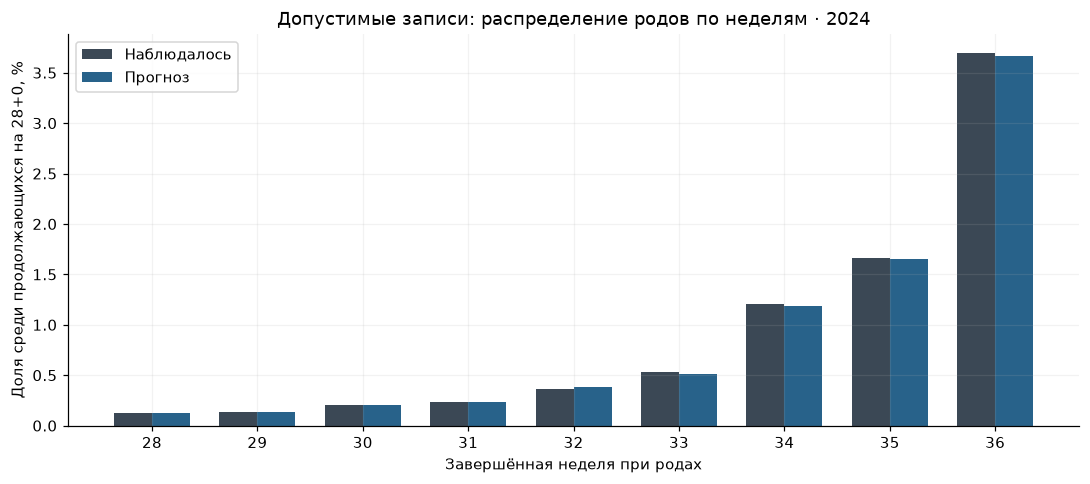

In [8]:
weekly_scope = serving["weekly_metrics"]
print("Недельный log loss:", round(weekly_scope["weekly_log_loss"], 5),
      "; частотный контроль:", round(weekly_scope["frequency_weekly_log_loss"], 5))
part = pd.DataFrame(serving["weekly_calibration"])
part = part.loc[part.birth_week.ne("37+")]
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(part))
ax.bar(x - .18, part.observed_rate * 100, width=.36, color=SLATE, label="Наблюдалось")
ax.bar(x + .18, part.mean_predicted * 100, width=.36, color=BLUE, label="Прогноз")
ax.set_xticks(x, part.birth_week.astype(str))
ax.set(xlabel="Завершённая неделя при родах", ylabel="Доля среди продолжающихся на 28+0, %",
       title="Допустимые записи: распределение родов по неделям · 2024")
ax.legend(); plt.tight_layout(); plt.show()

## Дополнительная диагностика · все записи 2024, включая пропуски

In [10]:
metrics, calibration = evaluate_week_profile()
main = metrics.loc[metrics.horizon.eq("before_37")].copy()
display(main[["landmark_week", "n_ongoing_live_births", "observed_rate", "mean_predicted", "auroc", "auprc", "brier", "weekly_log_loss", "frequency_weekly_log_loss"]].round(5))
short = metrics.loc[metrics.horizon.eq("next_4_weeks_preterm")].copy()
display(short[["landmark_week", "events", "observed_rate", "mean_predicted", "auroc", "auprc", "brier"]].round(5))
print("Частотный контроль для недельного log loss рассчитан на calibration 2023")

Частотный контроль для недельного log loss рассчитан на calibration 2023


,landmark_week,n_ongoing_live_births,observed_rate,mean_predicted,auroc,auprc,brier,weekly_log_loss,frequency_weekly_log_loss
0,20,3511757,0.08730,0.08685,0.64031,0.17507,0.07692,0.44439,0.45806
2,24,3506445,0.08592,0.08550,0.63963,0.17267,0.07585,0.43206,0.44540
4,28,3494404,0.08277,0.08222,0.63796,0.16634,0.07342,0.40660,0.41920
6,32,3469203,0.07611,0.07547,0.63465,0.15220,0.06824,0.35818,0.36936
8,34,3437195,0.06750,0.06687,0.62997,0.13319,0.06137,0.30428,0.31359
10,36,3335364,0.03904,0.03874,0.61651,0.07503,0.03703,0.16028,0.16487


,landmark_week,events,observed_rate,mean_predicted,auroc,auprc,brier
1,20,5312,0.00151,0.00149,0.68218,0.00371,0.00151
3,24,12041,0.00343,0.00357,0.67825,0.00915,0.00341
5,28,25201,0.00721,0.00729,0.66634,0.01865,0.00713
7,32,133839,0.03858,0.03822,0.64875,0.08648,0.03638
9,34,232027,0.06750,0.06687,0.62997,0.13319,0.06137
11,36,130196,0.03904,0.03874,0.61651,0.07503,0.03703


Максимальное отклонение среднего прогноза от доли по показанным децилям: 0.333 п.п.


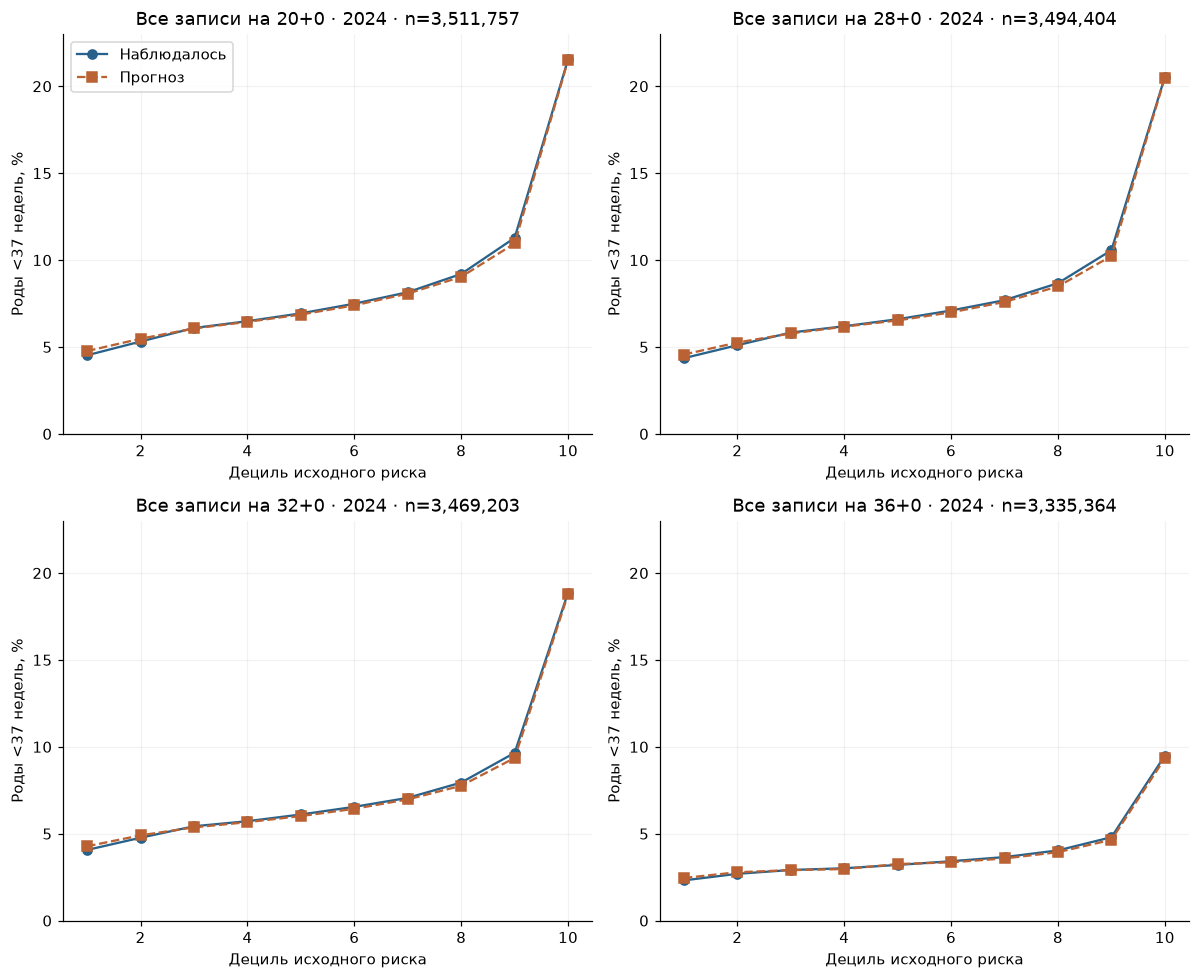

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, week in zip(axes.ravel(), [20, 28, 32, 36]):
    part = calibration.loc[(calibration.landmark_week.eq(week)) & (calibration.horizon.eq("before_37"))]
    n = int(main.loc[main.landmark_week.eq(week), "n_ongoing_live_births"].iloc[0])
    ax.plot(part.score_decile, 100 * part.observed_rate, "o-", color=BLUE, label="Наблюдалось")
    ax.plot(part.score_decile, 100 * part.mean_predicted, "s--", color=ORANGE, label="Прогноз")
    ax.set(xlabel="Дециль исходного риска", ylabel="Роды <37 недель, %", ylim=(0, 23), title=f"Все записи на {week}+0 · 2024 · n={n:,}")
axes[0, 0].legend(); plt.tight_layout(); plt.show()
cal_lt37 = calibration.loc[calibration.horizon.eq("before_37")]
print("Максимальное отклонение среднего прогноза от доли по показанным децилям:", round(100 * (cal_lt37.mean_predicted - cal_lt37.observed_rate).abs().max(), 3), "п.п.")

## Важность признаков

,feature,native_importance_percent,permutation_delta_log_loss
0,previous_preterm_birth,19.08920,0.00916
1,previous_live_births,22.20677,0.00446
2,prepregnancy_bmi,18.84494,0.00245
3,chronic_hypertension,7.11650,0.00245
4,maternal_age_at_birth,13.01522,0.00241
5,previous_cesarean,5.01004,0.00182
6,preexisting_diabetes,4.73765,0.00174
7,prepregnancy_cigarettes_per_day,4.77724,0.00088
8,previous_terminations,5.20243,0.00056


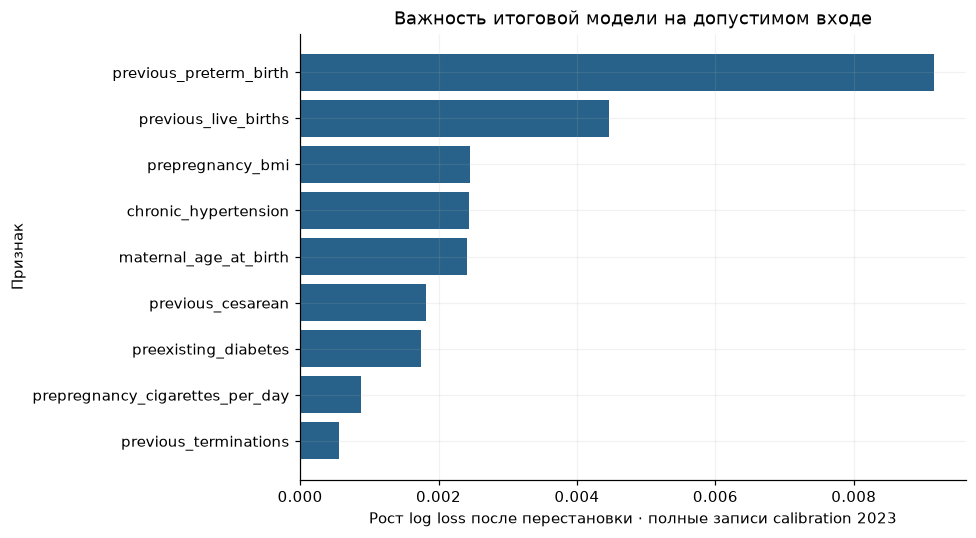

In [13]:
importance = pd.DataFrame(get_feature_importance())
display(importance.round(5))
plot = importance.sort_values("permutation_delta_log_loss")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot.feature, plot.permutation_delta_log_loss, color=BLUE)
ax.set(xlabel="Рост log loss после перестановки · полные записи calibration 2023", ylabel="Признак", title="Важность итоговой модели на допустимом входе")
plt.tight_layout(); plt.show()

## Прогноз для одной женщины · вымышленный профиль

In [15]:
woman = {"gestational_week": 28, "gestational_day": 3, "age_at_due_date_years": 30,
         "singleton_confirmed": True, "pregnancy_ongoing": True, "dating_confirmed": True,
         "prepregnancy_bmi": 24, "previous_live_births": 1, "previous_terminations": 0,
         "previous_preterm_birth": False, "chronic_hypertension": False,
         "preexisting_diabetes": False, "previous_cesarean": False,
         "prepregnancy_cigarettes_per_day": 0}
forecast = predict_woman(woman)
assert forecast["status"] == "OK"
display(pd.Series({k: v for k, v in forecast["probabilities"].items() if isinstance(v, float)}).rename("вероятность"))
assert predict_woman({**woman, "prepregnancy_bmi": None})["status"] == "INSUFFICIENT_DATA"
assert predict_woman({**woman, "previous_live_births": 0, "previous_preterm_birth": True})["status"] == "OOD"
print("Все маски прогноза:", forecast["missing_masks"])

Все маски прогноза: {'prepregnancy_bmi_missing': 0, 'previous_live_births_missing': 0, 'previous_terminations_missing': 0, 'previous_preterm_birth_missing': 0, 'chronic_hypertension_missing': 0, 'preexisting_diabetes_missing': 0, 'previous_cesarean_missing': 0, 'prepregnancy_cigarettes_per_day_missing': 0}


before_32_weeks                0.002574
before_34_weeks                0.006552
before_37_weeks                0.042714
preterm_within_next_4_weeks    0.003311
at_or_after_37_weeks           0.957286
Name: вероятность, dtype: float64

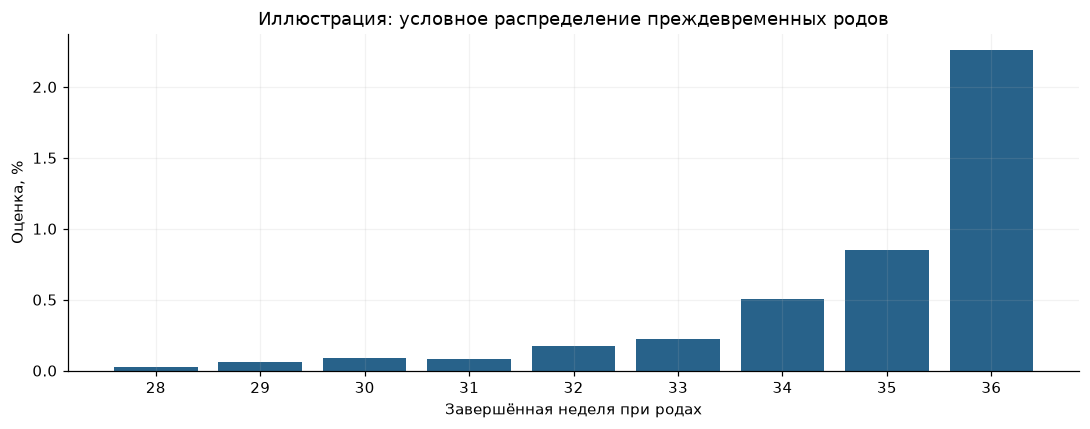

In [16]:
weekly = pd.DataFrame(forecast["probabilities"]["week_of_birth"])
assert np.isclose(weekly.probability.sum() + forecast["probabilities"]["at_or_after_37_weeks"], 1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(weekly.completed_week.astype(str), weekly.probability * 100, color=BLUE)
ax.set(xlabel="Завершённая неделя при родах", ylabel="Оценка, %", title="Иллюстрация: условное распределение преждевременных родов")
plt.tight_layout(); plt.show()

## Выводы

Проверка 2024 относится к **записям об одноплодных живорождениях США, переживших соответствующую неделю**. Для прямого ввода применяются правила полноты и области модели; таблица всех записей дана только как дополнительная диагностика. Модель различает исходы умеренно и мало улучшает три вопроса анамнеза. Средняя калибровка не гарантирует точность для отдельной женщины. В данных нет точной даты родов, визитов, цервикометрии, симптомов, вмешательств, мертворождений и типа начала родов. Недельный прогноз — приближение по завершённым неделям. Вымышленный профиль иллюстрирует формат результата. Поля и ограничения: [WOMAN_FORECAST_CONTRACT.md](WOMAN_FORECAST_CONTRACT.md).